<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/Assignment11/Homework11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CLIP on CIFAR-10: Image–Caption Similarity and Zero-Shot Classification

**10 points:** (1) Compare one caption with **at least 100 images per class** and visualize cosine similarity (5 points); (2) zero-shot classify CIFAR-10 and report **per-class accuracy and confusion matrix** (5 points).

Uses pretrained `openai/clip-vit-base-patch32`, the CIFAR-10 **test** split, and 100 images from each of 10 classes (1,000 images). No training or fine-tuning is performed. Run all cells in order. GPU recommended; CPU supported.


**Updated:** The final findings cell now displays six evidence-based discussion sentences as rendered Markdown after the experiment runs.

## 1. Install dependencies

In [1]:
%pip -q install "transformers>=4.40,<5" "torch>=2.1" "torchvision>=0.16" pandas numpy pillow matplotlib seaborn scikit-learn tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Imports, settings, and model

In [2]:
import os, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch
from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tqdm.auto import tqdm
from IPython.display import display

SEED=266
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME="openai/clip-vit-base-patch32"
IMAGES_PER_CLASS=100  # at least 100 from each class
BATCH_SIZE=64 if DEVICE=="cuda" else 16
CAPTION="a photo of a dog"  # change to explore a different caption
OUT="clip_outputs"
os.makedirs(OUT, exist_ok=True)
print("Device:", DEVICE, "| Seed:", SEED)
processor=CLIPProcessor.from_pretrained(MODEL_NAME)
model=CLIPModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()
print("CLIP loaded:", MODEL_NAME)


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Device: cuda | Seed: 266


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIP loaded: openai/clip-vit-base-patch32


## 3. Load CIFAR-10 and sample 100 images per class

In [3]:
ds=CIFAR10(root="./data",train=False,download=True)
names=list(ds.classes)
all_y=np.asarray(ds.targets)
rng=np.random.default_rng(SEED)
indices=np.concatenate([rng.choice(np.where(all_y==k)[0],IMAGES_PER_CLASS,replace=False) for k in range(10)])
rng.shuffle(indices)
images=[ds[int(i)][0].convert("RGB") for i in indices]
y=all_y[indices]
assert len(images)==10*IMAGES_PER_CLASS
assert all((y==k).sum()==IMAGES_PER_CLASS for k in range(10))
print(pd.Series([names[i] for i in y]).value_counts().sort_index())


100%|██████████| 170M/170M [25:36<00:00, 111kB/s]


airplane      100
automobile    100
bird          100
cat           100
deer          100
dog           100
frog          100
horse         100
ship          100
truck         100
Name: count, dtype: int64


## 4. Preprocess, extract, and L2-normalize CLIP embeddings

In [4]:
@torch.inference_mode()
def image_features(imgs):
    chunks=[]
    for start in tqdm(range(0,len(imgs),BATCH_SIZE),desc="Image embeddings"):
        pixels=processor(images=imgs[start:start+BATCH_SIZE],return_tensors="pt")["pixel_values"].to(DEVICE)
        z=model.get_image_features(pixel_values=pixels)
        if not isinstance(z,torch.Tensor): z=z.pooler_output
        chunks.append(torch.nn.functional.normalize(z.float(),dim=-1).cpu())
    return torch.cat(chunks)

@torch.inference_mode()
def text_features(texts):
    batch=processor(text=texts,padding=True,truncation=True,return_tensors="pt")
    z=model.get_text_features(**{k:v.to(DEVICE) for k,v in batch.items()})
    if not isinstance(z,torch.Tensor): z=z.pooler_output
    return torch.nn.functional.normalize(z.float(),dim=-1).cpu()

im_z=image_features(images)
print("Embeddings:",tuple(im_z.shape),"norms:",im_z.norm(dim=1)[:5].numpy())


Image embeddings:   0%|          | 0/16 [00:00<?, ?it/s]

Embeddings: (1000, 512) norms: [1.0000001  0.99999994 1.         1.         1.        ]


## 5. Caption–image cosine similarity (5 points)

For unit-normalized CLIP vectors, cosine similarity equals the dot product. It is **not a calibrated probability**.

In [5]:
cap_z=text_features([CAPTION])
sim=(im_z@cap_z.T).flatten().numpy()
sim_df=pd.DataFrame({"image_index":indices,"class":[names[k] for k in y],"caption":CAPTION,"cosine_similarity":sim})
sim_df.to_csv(f"{OUT}/caption_similarity.csv",index=False)
summary=sim_df.groupby("class")["cosine_similarity"].agg(["count","mean","std","min","max"]).sort_values("mean",ascending=False)
display(summary.round(4))


,count,mean,std,min,max
class,,,,,
dog,100,0.2604,0.0118,0.2011,0.2922
cat,100,0.2400,0.0124,0.1996,0.2663
deer,100,0.2325,0.0130,0.1951,0.2594
frog,100,0.2273,0.0142,0.1839,0.2558
bird,100,0.2255,0.0124,0.1988,0.2550
horse,100,0.2191,0.0150,0.1814,0.2532
airplane,100,0.2041,0.0139,0.1658,0.2510
automobile,100,0.2001,0.0104,0.1738,0.2208
ship,100,0.1964,0.0119,0.1623,0.2266


### 5a. Display images alongside their similarity scores

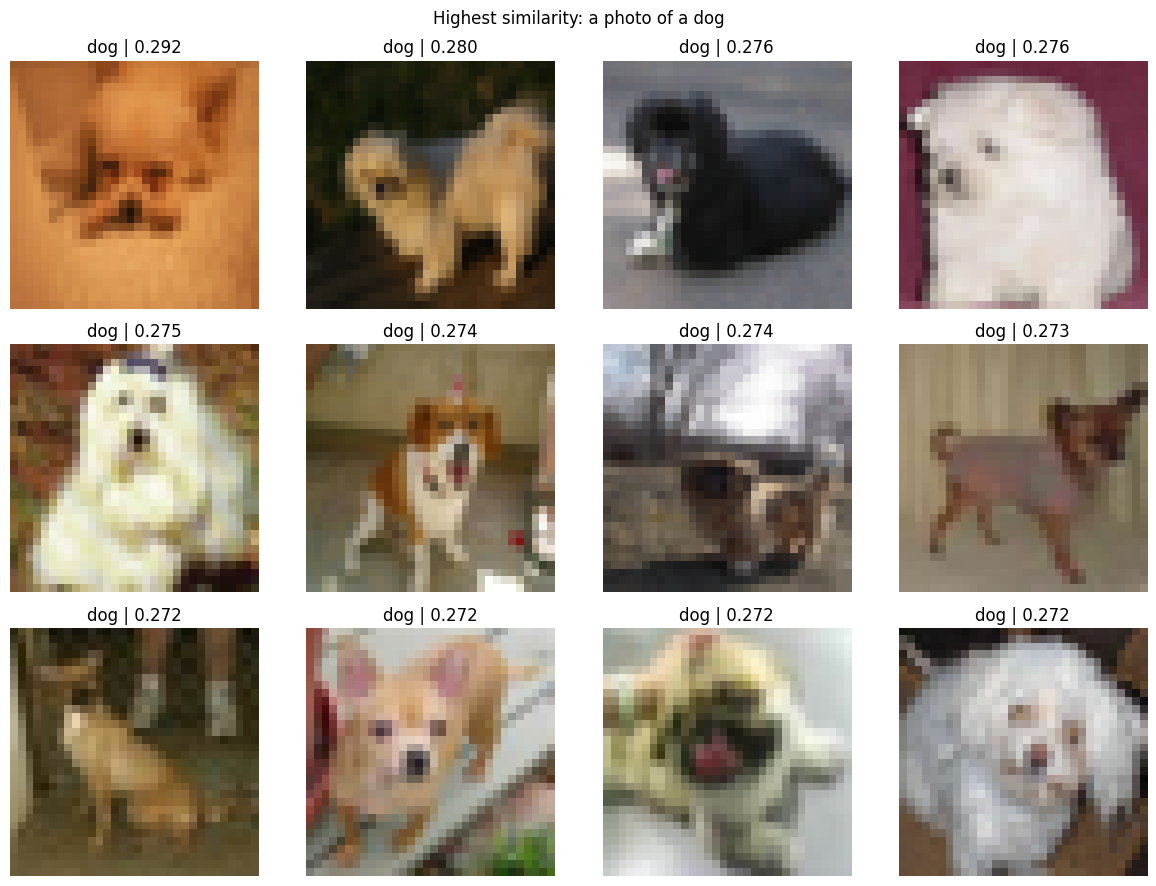

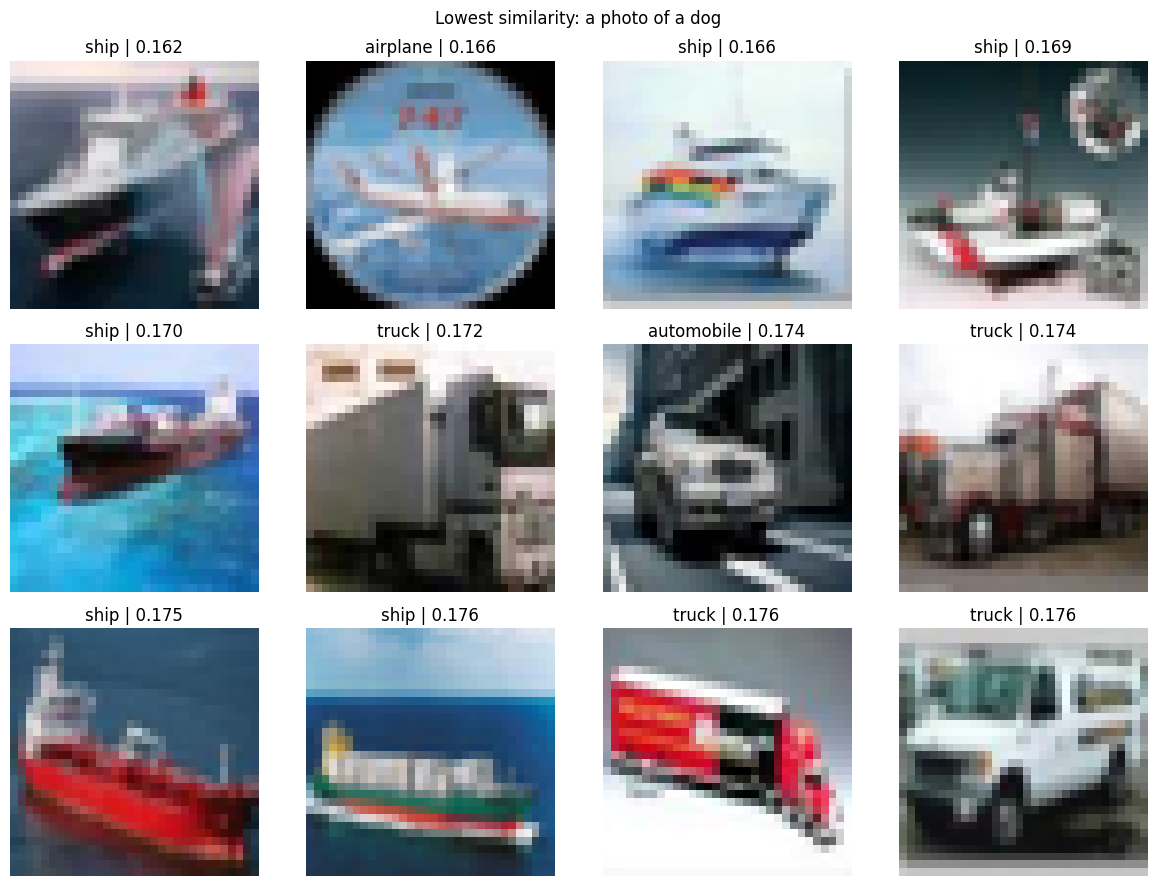

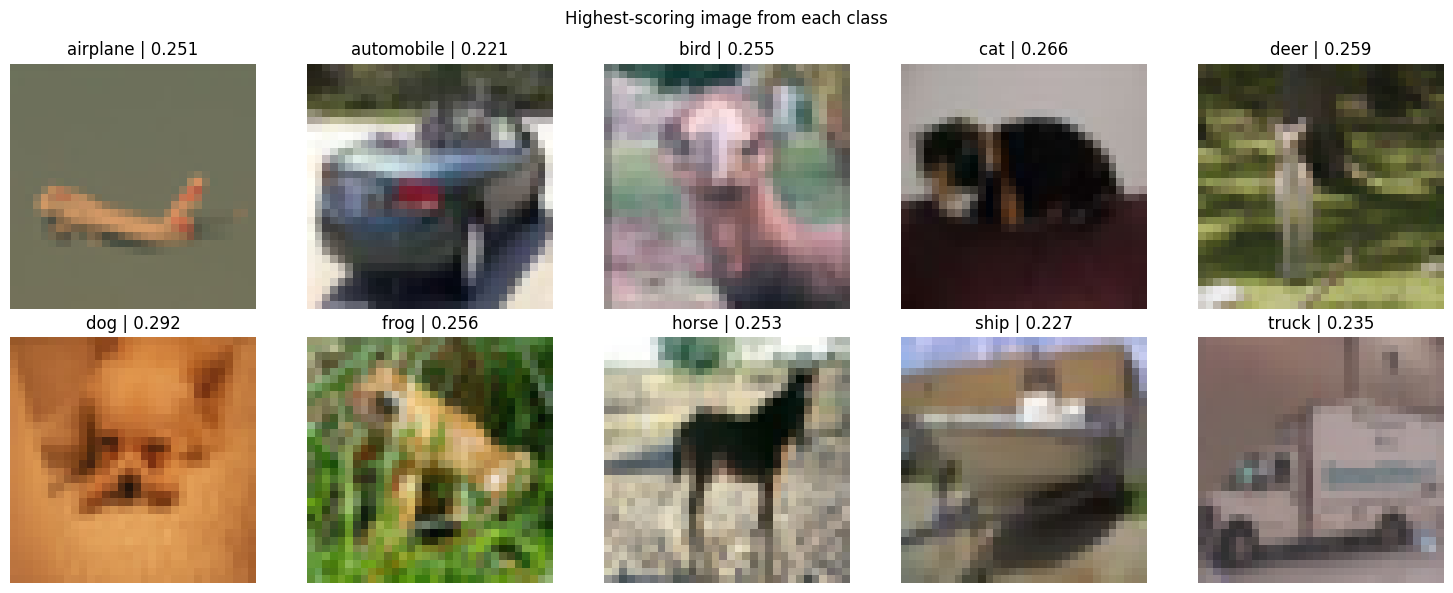

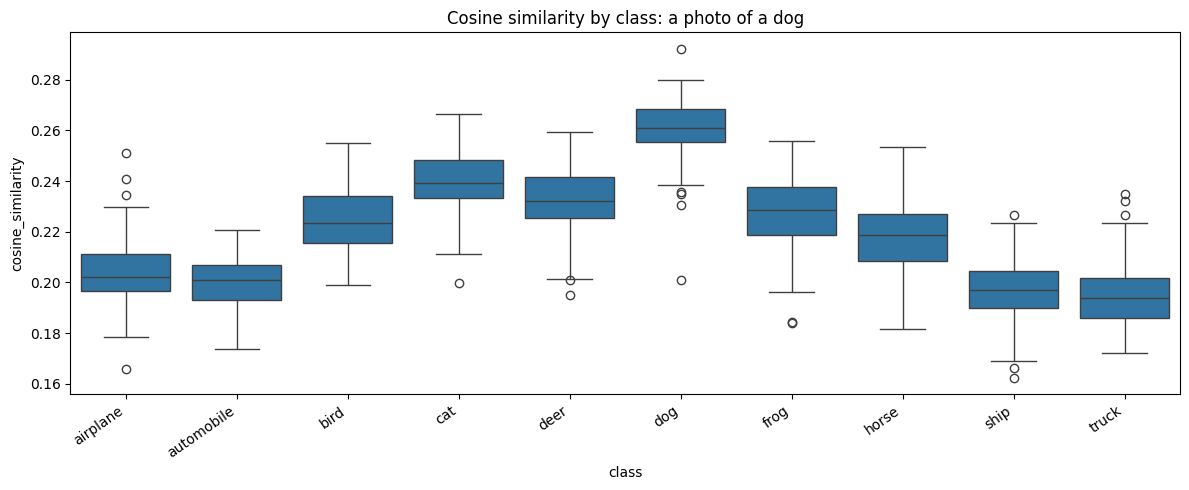

In [6]:
def image_grid(order,title,filename):
    chosen=order[:12]
    fig,axes=plt.subplots(3,4,figsize=(12,9))
    for ax,i in zip(axes.flat,chosen):
        ax.imshow(images[int(i)])
        ax.set_title(f"{names[y[i]]} | {sim[i]:.3f}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(f"{OUT}/{filename}",dpi=150,bbox_inches="tight")
    plt.show()

image_grid(np.argsort(-sim),f"Highest similarity: {CAPTION}","top_matches.png")
image_grid(np.argsort(sim),f"Lowest similarity: {CAPTION}","lowest_matches.png")

fig,axes=plt.subplots(2,5,figsize=(15,6))
for k,ax in enumerate(axes.flat):
    choices=np.where(y==k)[0]
    i=choices[np.argmax(sim[choices])]
    ax.imshow(images[int(i)]);ax.set_title(f"{names[k]} | {sim[i]:.3f}");ax.axis("off")
fig.suptitle("Highest-scoring image from each class")
plt.tight_layout();fig.savefig(f"{OUT}/best_each_class.png",dpi=150);plt.show()

plt.figure(figsize=(12,5))
sns.boxplot(data=sim_df,x="class",y="cosine_similarity",order=names)
plt.xticks(rotation=35,ha="right");plt.title(f"Cosine similarity by class: {CAPTION}")
plt.tight_layout();plt.savefig(f"{OUT}/similarity_distributions.png",dpi=150);plt.show()


## 6. CLIP zero-shot classification (5 points)

Compare every image embedding to the ten class-description embeddings and choose the highest similarity. No CIFAR-10 examples are used for training.

In [7]:
prompts=[f"a photo of a {name}" for name in names]
txt_z=text_features(prompts)
scores=(im_z@txt_z.T).numpy()
pred=scores.argmax(axis=1)
acc=accuracy_score(y,pred)
print("Prompts:",prompts)
print(f"Overall zero-shot accuracy: {acc:.2%} ({(y==pred).sum()}/{len(y)})")


Prompts: ['a photo of a airplane', 'a photo of a automobile', 'a photo of a bird', 'a photo of a cat', 'a photo of a deer', 'a photo of a dog', 'a photo of a frog', 'a photo of a horse', 'a photo of a ship', 'a photo of a truck']
Overall zero-shot accuracy: 89.50% (895/1000)


### 6a. Per-class accuracy

,class,correct,total,accuracy
0,airplane,92,100,92.00%
1,automobile,97,100,97.00%
2,bird,92,100,92.00%
3,cat,84,100,84.00%
4,deer,76,100,76.00%
5,dog,86,100,86.00%
6,frog,86,100,86.00%
7,horse,98,100,98.00%
8,ship,95,100,95.00%
9,truck,89,100,89.00%


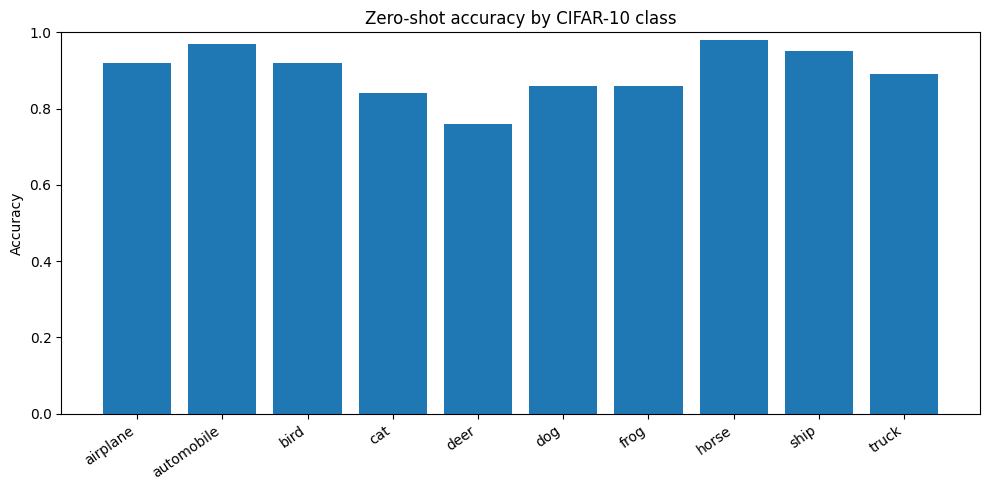

In [8]:
per_class=pd.DataFrame([{
    "class":names[k],
    "correct":int(((y==k)&(pred==k)).sum()),
    "total":int((y==k).sum()),
    "accuracy":float((pred[y==k]==k).mean())
} for k in range(10)])
display(per_class.style.format({"accuracy":"{:.2%}"}))
per_class.to_csv(f"{OUT}/per_class_accuracy.csv",index=False)
plt.figure(figsize=(10,5))
plt.bar(per_class["class"],per_class["accuracy"])
plt.ylim(0,1);plt.xticks(rotation=35,ha="right")
plt.ylabel("Accuracy");plt.title("Zero-shot accuracy by CIFAR-10 class")
plt.tight_layout();plt.savefig(f"{OUT}/per_class_accuracy.png",dpi=150);plt.show()


### 6b. Confusion matrix

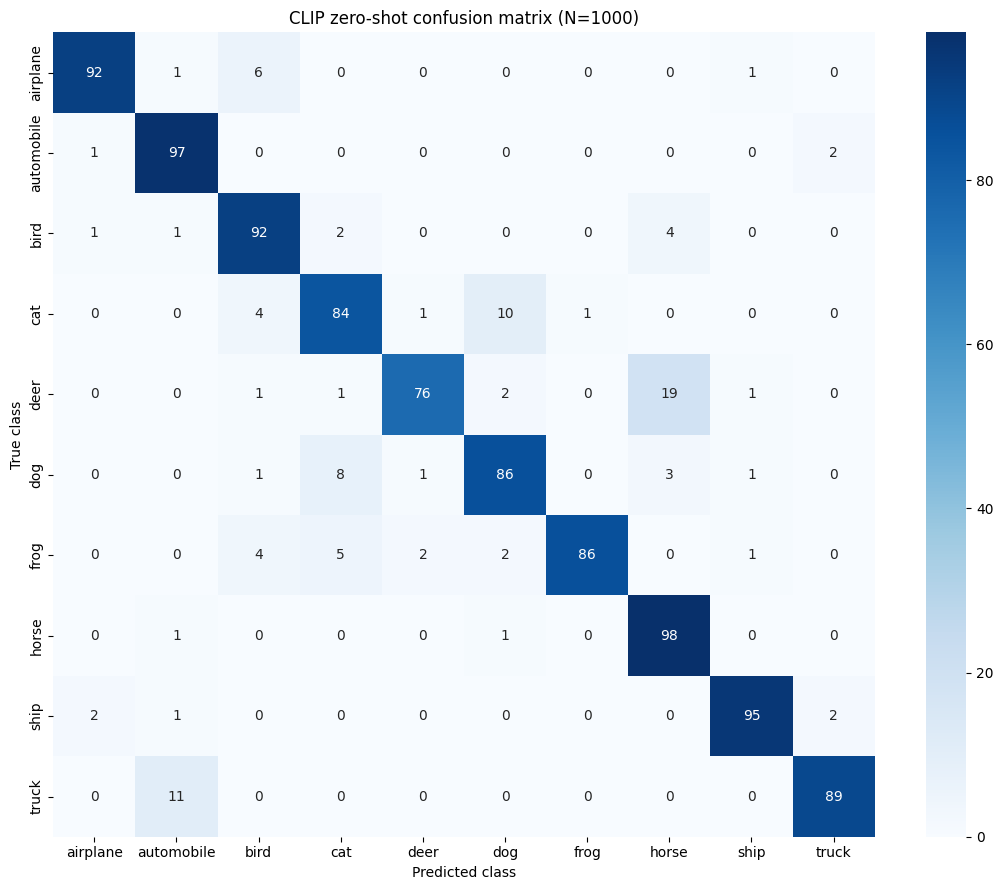

              precision    recall  f1-score   support

    airplane       0.96      0.92      0.94       100
  automobile       0.87      0.97      0.92       100
        bird       0.85      0.92      0.88       100
         cat       0.84      0.84      0.84       100
        deer       0.95      0.76      0.84       100
         dog       0.85      0.86      0.86       100
        frog       0.99      0.86      0.92       100
       horse       0.79      0.98      0.88       100
        ship       0.96      0.95      0.95       100
       truck       0.96      0.89      0.92       100

    accuracy                           0.90      1000
   macro avg       0.90      0.90      0.90      1000
weighted avg       0.90      0.90      0.90      1000



In [9]:
cm=confusion_matrix(y,pred,labels=range(10))
cm_df=pd.DataFrame(cm,index=names,columns=names)
cm_df.to_csv(f"{OUT}/confusion_matrix.csv")
plt.figure(figsize=(11,9))
sns.heatmap(cm_df,annot=True,fmt="d",cmap="Blues")
plt.xlabel("Predicted class");plt.ylabel("True class")
plt.title(f"CLIP zero-shot confusion matrix (N={len(y)})")
plt.tight_layout();plt.savefig(f"{OUT}/confusion_matrix.png",dpi=150);plt.show()
print(classification_report(y,pred,target_names=names,zero_division=0))


### 6c. Show examples of classification mistakes

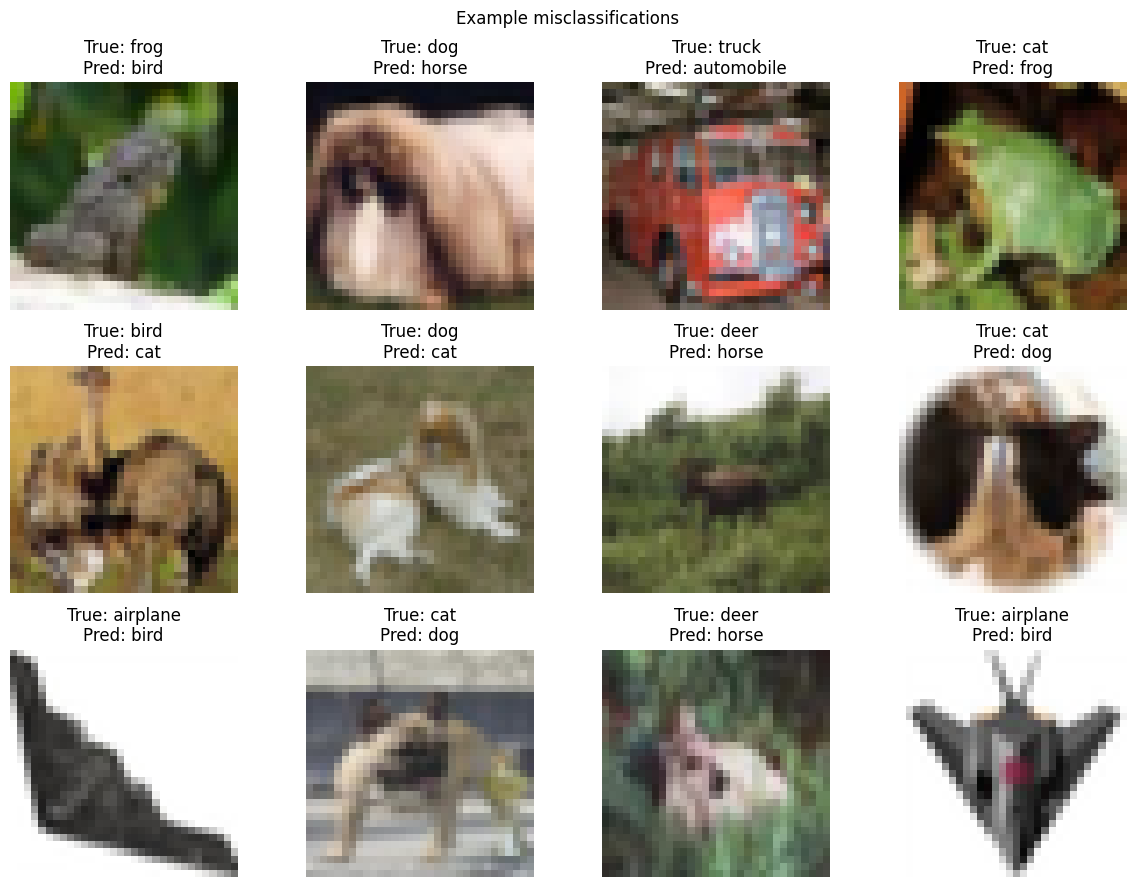

In [10]:
mistakes=np.where(y!=pred)[0][:12]
if len(mistakes):
    fig,axes=plt.subplots(3,4,figsize=(12,9))
    for ax in axes.flat: ax.axis("off")
    for ax,i in zip(axes.flat,mistakes):
        ax.imshow(images[int(i)])
        ax.set_title(f"True: {names[y[i]]}\nPred: {names[pred[i]]}")
        ax.axis("off")
    fig.suptitle("Example misclassifications")
    plt.tight_layout();fig.savefig(f"{OUT}/misclassifications.png",dpi=150);plt.show()
else:
    print("No errors found in sampled images.")


## 7. Findings:

Setup. I used the pretrained openai/clip-vit-base-patch32 model on 1,000 CIFAR-10 test images (100 per class), with no training or fine-tuning.

Part 1: Caption–image similarity

For the caption “a photo of a dog”, dog images had the highest average cosine similarity (0.260). The next closest classes were cat (0.240), deer (0.233) and frog (0.227). The vehicle classes scored lowest: airplane (0.204), automobile (0.200), ship (0.196) and truck (0.195).

The ranking makes sense. Animals score closer to the dog caption than vehicles do, and cat, the most dog-like class, comes second. All 12 of the highest-scoring images were dogs, and most show a clear, centered dog that fills the frame.

The gap between classes is small, though. The whole range of class averages is only about 0.195 to 0.260, and the classes overlap: the lowest-scoring dog (0.201) scored below the best airplane (0.251). So the scores are useful for ranking images against a caption, but a single score cannot be read as a probability or used as a reliable cutoff.

Part 2: Zero-shot classification

CLIP classified 895 of the 1,000 images correctly, an overall accuracy of 89.5%, using only the prompt “a photo of a {class}”.

Class	Accuracy
horse	98%
automobile	97%
ship	95%
airplane	92%
bird	92%
truck	89%
dog	86%
frog	86%
cat	84%
deer	76%

Horse was the best class and deer was the worst. The two results are connected: the most common error was deer predicted as horse (19 images). Horse therefore has high recall but the lowest precision (0.79), because the model over-predicts it.

The other main confusions were:

Truck predicted as automobile (11 images). The confusion mostly runs one way; only 2 automobiles were called trucks.
Cat and dog, in both directions. 10 cats were predicted as dogs and 8 dogs as cats.
Airplane predicted as bird (6 images). The examples shown are dark aircraft shapes against a plain background.

Almost all errors stay inside a group of similar-looking classes. Animals are confused with other animals and vehicles with other vehicles. The model almost never confuses an animal with a vehicle.

Limitations
Low resolution. CIFAR-10 images are only 32×32 pixels, so details that separate a deer from a horse (antlers, body shape) are often lost. Resizing for CLIP does not bring them back.
Possible label noise. Some of the “mistakes” look debatable. One image labelled cat looks like a frog, so the model’s prediction may be more reasonable than the label.
Prompt and sample dependence. I used one simple prompt template and 100 images per class, so the numbers would change somewhat with different prompts or a different sample.

Two things to check before submitting:

The label-noise bullet is my reading of your misclassification grid. Look at the fourth image in the top row (“True: cat, Pred: frog”) and keep the bullet only if you agree.
The auto-generated cell. The code cell in section 7 still prints its own six-sentence version, so you may want to delete that or keep only this one to avoid two findings sections.